In [2]:
import pandas as pd
import numpy as np

chosen_year = "2023"


market = pd.read_pickle(f'./full_market/{chosen_year}.pkl')

In [ ]:
gainers = market[market["Gainer"] == True]
losers = market[market["Loser"] == True]

print(market.mean()["Prop 5 to -20 Day Avg Volume"])
print(gainers.mean()["Prop 5 to -20 Day Avg Volume"])
print(losers.mean()["Prop 5 to -20 Day Avg Volume"])

1.0348870442320366
1.1787508910232294
1.2542560038192692


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                  0.003
Method:                 Least Squares   F-statistic:                     16.17
Date:                Fri, 22 Nov 2024   Prob (F-statistic):           5.87e-05
Time:                        00:34:19   Log-Likelihood:                 8994.0
No. Observations:                5619   AIC:                        -1.798e+04
Df Residuals:                    5617   BIC:                        -1.797e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0027      0.002     -1.789      0.0

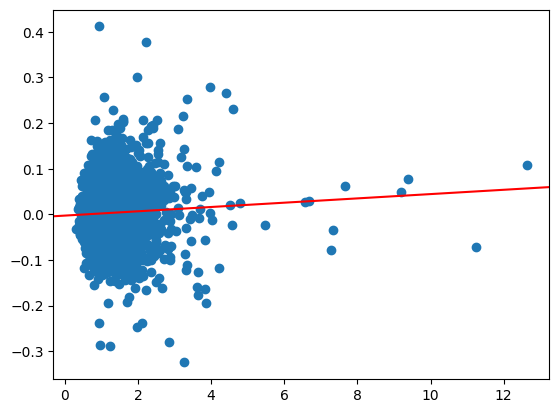

In [ ]:
import statsmodels.api as sm
import numpy as np

dataset = gainers

independent = ["Prop 5 to -20 Day Avg Volume"]
dependent = ["Percent 1 Week Growth"]

dataset = dataset.dropna(subset=[*independent, *dependent])

X = dataset[independent].apply(pd.to_numeric, errors='coerce')
y = dataset[dependent].apply(pd.to_numeric, errors='coerce')

# Align X and y to ensure they have the same indices and drop NaNs
X, y = X.align(y, join='inner', axis=0)

# Ensure all data is numeric
X = X.apply(pd.to_numeric, errors='coerce')
y = y.apply(pd.to_numeric, errors='coerce')

X = sm.add_constant(X)

# Convert to numpy arrays
X = np.asarray(X, dtype=np.float64)
y = np.asarray(y, dtype=np.float64)

print(sm.OLS(y, X).fit().summary())

results = sm.OLS(y, X).fit()

import matplotlib.pyplot as plt
plt.scatter(dataset[independent], dataset[dependent])
fig = sm.graphics.abline_plot(model_results=results, color='red', ax=plt.gca())

Regression for dummy 20 percent
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.004
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     26.98
Date:                Fri, 15 Nov 2024   Prob (F-statistic):           2.13e-07
Time:                        02:20:41   Log-Likelihood:                 9828.8
No. Observations:                6025   AIC:                        -1.965e+04
Df Residuals:                    6023   BIC:                        -1.964e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.006

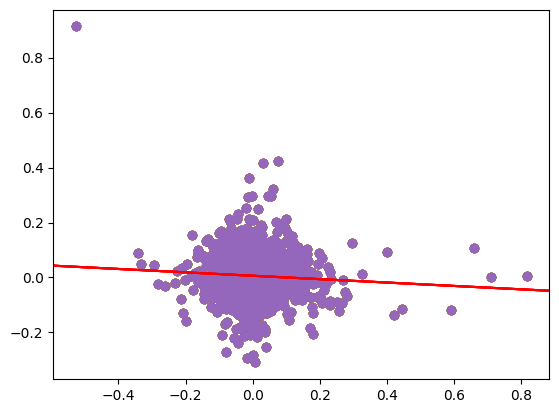

In [ ]:
# import statsmodels.api as sm
# import numpy as np
# import matplotlib.pyplot as plt

# gainers_data_dummies = pd.get_dummies(pd.concat(gainers_day_percentiles, names=["Percent Change Dummy"], keys=[f'{(i+1)*20}' for i in range(len(gainers_day_percentiles))]).reset_index(level=0), columns=["Percent Change Dummy"])
# gainers_data_dummies["Bottom 1 Week"] = gainers_data_dummies.index.isin(f1w_gainers_data_percentiles[-1].index)

# # Ensure all data is numeric and drop rows with NaNs
# for i in range(20,120,20):
#     # X = gainers_data_dummies[[f"Percent Change Dummy_{i}", "Bottom 1 Week"]].apply(pd.to_numeric, errors='coerce')
#     X = gainers_data_dummies["Percent 1 Week Growth"].apply(pd.to_numeric, errors='coerce')
#     y = gainers_data_dummies["Percent 1 to 2 Week Growth"].apply(pd.to_numeric, errors='coerce')

#     # Align X and y to ensure they have the same indices and drop NaNs
#     X, y = X.align(y, join='inner', axis=0)

#     # Drop NaNs
#     X = X.dropna()
#     y = y.loc[X.index]
#     y = y.dropna()
#     X = X.loc[y.index]

#     # Ensure all data is numeric
#     X = X.apply(pd.to_numeric, errors='coerce')
#     y = y.apply(pd.to_numeric, errors='coerce')

#     X = sm.add_constant(X)

#     # Convert to numpy arrays
#     X = np.asarray(X, dtype=np.float64)
#     y = np.asarray(y, dtype=np.float64)

#     print("Regression for dummy {} percent".format(i))
#     results = sm.OLS(y, X).fit()
#     print(results.summary())

#     plt.scatter(gainers_data_dummies['Percent 1 Week Growth'], gainers_data_dummies['Percent 1 to 2 Week Growth'])
#     fig = sm.graphics.abline_plot(model_results=results, color='red', ax=plt.gca())

    

In [19]:
# import statsmodels.api as sm
# import numpy as np

# gain_lose_dummies = pd.concat([losers_data, gainers_data], names=["Loser"], keys=[True, False]).reset_index(level=0)

# gain_lose_dummies_dropped = gain_lose_dummies.dropna(subset=["Percent 1 Week Growth"])

# X = gain_lose_dummies_dropped["Loser"].apply(pd.to_numeric, errors='coerce')
# y = gain_lose_dummies_dropped["Percent 1 Week Growth"].apply(pd.to_numeric, errors='coerce')

# # Align X and y to ensure they have the same indices and drop NaNs
# X, y = X.align(y, join='inner', axis=0)

# # Drop NaNs
# # X = X.dropna()
# # y = y.loc[X.index]
# # y = y.dropna()
# # X = X.loc[y.index]



# # Ensure all data is numeric
# X = X.apply(pd.to_numeric, errors='coerce')
# y = y.apply(pd.to_numeric, errors='coerce')

# X = sm.add_constant(X)

# # Convert to numpy arrays
# X = np.asarray(X, dtype=np.float64)
# y = np.asarray(y, dtype=np.float64)

# print(sm.OLS(y, X).fit().summary())


In [20]:
# import statsmodels.api as sm
# import numpy as np


# gainer_tails_dummies = pd.concat([pd.concat([gainers_data_percentiles[0], gainers_data_percentiles[-1]], names=["Top_Tail"], keys=[True, False]).reset_index(level=0), pd.concat([losers_data_percentiles[0], losers_data_percentiles[-1]], names=["Top_Tail"], keys=[True, False]).reset_index(level=0)], names=["Gainer"], keys=[True, False]).reset_index(level=0)

# gainer_tails_dummies = gainer_tails_dummies.dropna(subset=["Percent 1 to 2 Week Growth"])


# X = gainer_tails_dummies[["Top_Tail", "Gainer"]].apply(pd.to_numeric, errors='coerce')
# y = gainer_tails_dummies["Percent 1 to 2 Week Growth"].apply(pd.to_numeric, errors='coerce')

# # Align X and y to ensure they have the same indices and drop NaNs
# X, y = X.align(y, join='inner', axis=0)

# # Drop NaNs
# # X = X.dropna()
# # y = y.loc[X.index]
# # y = y.dropna()
# # X = X.loc[y.index]



# # Ensure all data is numeric
# X = X.apply(pd.to_numeric, errors='coerce')
# y = y.apply(pd.to_numeric, errors='coerce')

# X = sm.add_constant(X)

# # Convert to numpy arrays
# X = np.asarray(X, dtype=np.float64)
# y = np.asarray(y, dtype=np.float64)

# print(sm.OLS(y, X).fit().summary())
